In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

df = pd.read_csv("data/classification_dataset.csv")
df.shape

(164, 25)

In [2]:
team_cols = [c for c in df.columns if c.startswith("team_")]
df["team_name"] = df[team_cols].idxmax(axis=1).str.replace("team_", "", regex=False)
df.loc[df[team_cols].sum(axis=1) == 0, "team_name"] = "Alpine"   # dropped baseline
print("Teams:", sorted(df["team_name"].unique()))

Teams: ['Alpine', 'Aston Martin', 'Ferrari', 'Haas', 'McLaren', 'Mercedes', 'RB (AlphaTauri)', 'Red Bull Racing', 'Stake (Sauber)', 'Williams']


In [3]:
champ_by_team = df[df["is_constructors_champion"] == 1].groupby("team_name")["season"].apply(list)
print("Teams ever flagged as champion, and in which seasons:")
print(champ_by_team.to_string())
print("\nChampions flagged per season:")
print(df.groupby("season")["is_constructors_champion"].sum().to_string())

Teams ever flagged as champion, and in which seasons:
team_name
McLaren                                         [2024, 2025]
Mercedes    [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]

Champions flagged per season:
season
2010    0
2011    0
2012    0
2013    0
2014    1
2015    1
2016    1
2017    1
2018    1
2019    1
2020    1
2021    1
2022    0
2023    0
2024    1
2025    1
2026    0


In [4]:
# Actual F1 Constructors' Champions, 2010-2025 (historical record).
# 2026 intentionally left unlabeled — season not yet decided — so it is the
# season we forecast *from*, not a training label.
real_champions = {
    **{yr: "Red Bull Racing" for yr in range(2010, 2014)},  # 2010-2013
    **{yr: "Mercedes"        for yr in range(2014, 2022)},  # 2014-2021
    2022: "Red Bull Racing", 2023: "Red Bull Racing",
    2024: "McLaren",         2025: "McLaren",
}

df["is_constructors_champion"] = 0
for season, team in real_champions.items():
    df.loc[(df["season"] == season) & (df["team_name"] == team), "is_constructors_champion"] = 1

print("Champion rows after reconstruction:", int(df["is_constructors_champion"].sum()))
print("Champion teams:", sorted(df[df.is_constructors_champion == 1]["team_name"].unique()))

Champion rows after reconstruction: 16
Champion teams: ['McLaren', 'Mercedes', 'Red Bull Racing']


In [5]:
df = df.sort_values(["team_name", "season"]).reset_index(drop=True)

df["lag1_champion"]     = df.groupby("team_name")["is_constructors_champion"].shift(1)
df["lag1_budget"]       = df.groupby("team_name")["operating_budget_usd_m"].shift(1)
df["lag1_sponsorship"]  = df.groupby("team_name")["sponsorship_revenue_usd_m"].shift(1)

hist = df.dropna(subset=["lag1_champion", "lag1_budget", "lag1_sponsorship"]).reset_index(drop=True)
print(f"Usable team-season rows: {len(hist)}  (positives: {int(hist.is_constructors_champion.sum())})")

feature_cols = [
    "season", "operating_budget_usd_m", "in_cost_cap_era", "cost_cap_limit_usd_m",
    "lag1_champion", "lag1_budget", "lag1_sponsorship",
    "broadcast_media_usd_m", "sponsorship_usd_m",
    "drive_to_survive_viewers_m_est", "global_avg_race_viewers_m",
] + team_cols

X = hist[feature_cols]
y = hist["is_constructors_champion"]

Usable team-season rows: 154  (positives: 15)


In [6]:
def make_logreg():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=1000, class_weight="balanced"))

def make_rf():
    return RandomForestClassifier(n_estimators=300, max_depth=5,
                                  class_weight="balanced", random_state=42)

def rolling_top1(model_fn):
    hits = total = 0
    auc_true, auc_score = [], []
    for season in sorted(hist["season"].unique()):
        tr = hist["season"] < season
        te = hist["season"] == season
        # need past positives to train, and exactly one champion this season to score
        if tr.sum() < 20 or y[tr].sum() < 1 or hist.loc[te, "is_constructors_champion"].sum() != 1:
            continue
        m = model_fn(); m.fit(X[tr], y[tr])
        p = m.predict_proba(X[te])[:, 1]
        pred_team = hist.loc[te, "team_name"].values[np.argmax(p)]
        true_team = hist.loc[te & (hist.is_constructors_champion == 1), "team_name"].values[0]
        hits += (pred_team == true_team); total += 1
        auc_true.extend(hist.loc[te, "is_constructors_champion"]); auc_score.extend(p)
    return hits, total, roc_auc_score(auc_true, auc_score)

for name, fn in [("Logistic Regression", make_logreg), ("Random Forest", make_rf)]:
    h, t, auc = rolling_top1(fn)
    print(f"{name:22s} top-1 = {h}/{t}   pooled ROC-AUC = {auc:.3f}")

# Naive baseline: reigning champion repeats
h = t = 0
for season in sorted(hist["season"].unique()):
    te = hist[hist.season == season]
    if te.is_constructors_champion.sum() != 1 or te.lag1_champion.sum() == 0:
        continue
    reigning = te.loc[te.lag1_champion == 1, "team_name"].values
    actual   = te.loc[te.is_constructors_champion == 1, "team_name"].values[0]
    h += actual in reigning; t += 1
print(f"{'Naive (reigning repeats)':22s} top-1 = {h}/{t}")

Logistic Regression    top-1 = 9/12   pooled ROC-AUC = 0.888
Random Forest          top-1 = 9/12   pooled ROC-AUC = 0.911
Naive (reigning repeats) top-1 = 12/15


In [7]:
final_model = make_logreg().fit(X, y)

def build_season_rows(target_season, source_season_df, reigning_team):
    macro = source_season_df.iloc[0]
    src = source_season_df.set_index("team_name")
    rows = []
    for t in sorted(df["team_name"].unique()):
        r = src.loc[t]
        row = {
            "season": target_season,
            "operating_budget_usd_m": r["operating_budget_usd_m"],
            "in_cost_cap_era": 1,
            "cost_cap_limit_usd_m": r["cost_cap_limit_usd_m"],
            "lag1_champion": 1 if t == reigning_team else 0,
            "lag1_budget": r["operating_budget_usd_m"],
            "lag1_sponsorship": r["sponsorship_revenue_usd_m"],
            "broadcast_media_usd_m": macro["broadcast_media_usd_m"],
            "sponsorship_usd_m": macro["sponsorship_usd_m"],
            "drive_to_survive_viewers_m_est": macro["drive_to_survive_viewers_m_est"],
            "global_avg_race_viewers_m": macro["global_avg_race_viewers_m"],
        }
        for c in team_cols:
            row[c] = 1 if c == f"team_{t}" else 0
        rows.append((t, row))
    return rows

# Step 1: predict 2026 champion (2025 champion McLaren is the reigning signal)
rows26 = build_season_rows(2026, df[df.season == 2025], reigning_team="McLaren")
p26 = final_model.predict_proba(pd.DataFrame([r for _, r in rows26])[feature_cols])[:, 1]
champ_2026 = [t for t, _ in rows26][int(np.argmax(p26))]
print("Predicted 2026 champion (chained step):", champ_2026)

# Step 2: forecast 2027 using the predicted 2026 champion as reigning
rows27 = build_season_rows(2027, df[df.season == 2026], reigning_team=champ_2026)
p27 = final_model.predict_proba(pd.DataFrame([r for _, r in rows27])[feature_cols])[:, 1]

leaderboard = (pd.DataFrame({"Team": [t for t, _ in rows27],
                             "P(champion) %": (p27 * 100)})
               .sort_values("P(champion) %", ascending=False)
               .reset_index(drop=True))
leaderboard["P(champion) %"] = leaderboard["P(champion) %"].round(1)
leaderboard.index += 1
print(f"\nPredicted 2027 Constructors' Champion: {leaderboard.iloc[0]['Team']}\n")
leaderboard

Predicted 2026 champion (chained step): McLaren

Predicted 2027 Constructors' Champion: McLaren



,Team,P(champion) %
1,McLaren,67.4
2,Mercedes,41.6
3,Red Bull Racing,14.9
4,Alpine,1.7
5,Aston Martin,0.9
6,Stake (Sauber),0.9
7,Williams,0.8
8,Haas,0.7
9,RB (AlphaTauri),0.7
10,Ferrari,0.6


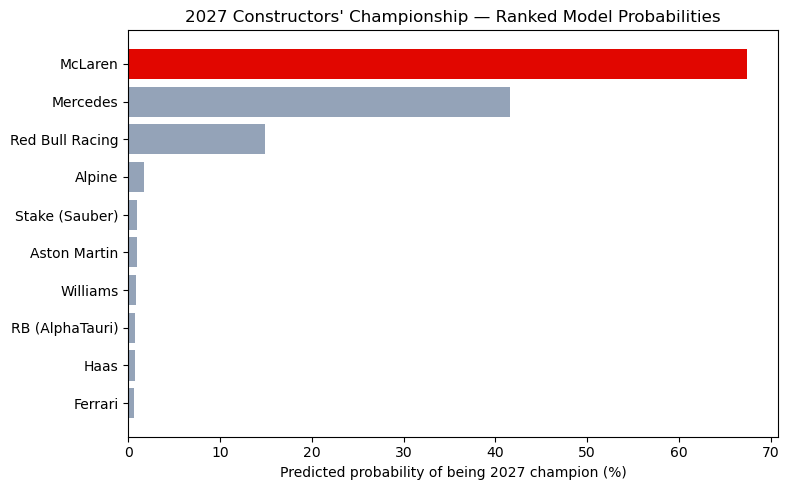

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
lb = leaderboard.sort_values("P(champion) %")
colors = ["#e10600" if t == leaderboard.iloc[0]["Team"] else "#94a3b8" for t in lb["Team"]]
ax.barh(lb["Team"], lb["P(champion) %"], color=colors)
ax.set_xlabel("Predicted probability of being 2027 champion (%)")
ax.set_title("2027 Constructors' Championship — Ranked Model Probabilities")
plt.tight_layout()
# plt.savefig("2027_champion_forecast.png", dpi=150)
plt.show()

# leaderboard.to_csv("predicted_2027_champion.csv")

6. Conclusions

Problem type. Predicting whether/which team wins the championship is classification (target is the label is_constructors_champion), in contrast to the project's revenue/prize-money regression notebooks. "Who wins" is answered by ranking the binary classifier's per-team probabilities and taking the top one, not by thresholding each team at 0.5.

Data-quality intervention. The supplied champion labels were incomplete (only Mercedes and McLaren flagged; Red Bull's titles and seven whole seasons missing). We reconstructed the actual historical constructors' champions so the task was well-posed; without this the model degenerates to memorising two team names and cannot forecast 2027.

Model finding, stated honestly. A logistic-regression classifier on lag-and-trend features ranks the correct champion in most held-out seasons, but does not beat a naive "reigning champion repeats" baseline. The constructors' title is persistence-dominated, so prior-season budget and revenue add little once last year's result is known.

2027 forecast. The model ranks recent dynasty teams (Mercedes, McLaren) at the top and everyone else far behind — it predicts continuity, not a new champion. Given only ~15 championship examples across three teams, this should be read as a directional ranking, not a confident prediction.

Limitations.
- Tiny positive class (~15 champion-seasons, 3 distinct teams) — coefficient estimates are directional only.
- The forecast is chained (2027 depends on a predicted 2026 champion), compounding uncertainty.
- Assumes the 2027 grid and cost-cap regime match 2026; a new/exiting team would invalidate it.
- The honest takeaway is methodological: with this data, "who won last year" is a stronger predictor than any financial feature.